Explainability Using SHAP for LightGBM

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Import libraries

In [ ]:
import os
import json
import joblib
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

SEED = 42
HORIZON = 28

np.random.seed(SEED)

print("Step 14 libraries loaded.")

Step 14 libraries loaded.


nstall/import SHAP

In [ ]:
PROJECT_DIR = "/content/drive/MyDrive/GC210_Retail_Forecasting"

PROCESSED_DIR = os.path.join(
    PROJECT_DIR,
    "data",
    "processed"
)

SUPERVISED_DIR = os.path.join(
    PROCESSED_DIR,
    "supervised"
)

MODEL_DIR = os.path.join(
    PROJECT_DIR,
    "models"
)

RESULTS_DIR = os.path.join(
    PROJECT_DIR,
    "results"
)

METRICS_DIR = os.path.join(
    RESULTS_DIR,
    "metrics"
)

FIGURES_DIR = os.path.join(
    RESULTS_DIR,
    "figures"
)

SHAP_DIR = os.path.join(
    RESULTS_DIR,
    "shap"
)

SHAP_FIGURES_DIR = os.path.join(
    SHAP_DIR,
    "figures"
)

SHAP_TABLES_DIR = os.path.join(
    SHAP_DIR,
    "tables"
)

for folder in [
    SHAP_DIR,
    SHAP_FIGURES_DIR,
    SHAP_TABLES_DIR
]:
    os.makedirs(
        folder,
        exist_ok=True
    )

print("SHAP directories created.")

SHAP directories created.


Define project paths

In [ ]:
PROJECT_DIR = "/content/drive/MyDrive/GC210_Retail_Forecasting"

PROCESSED_DIR = os.path.join(
    PROJECT_DIR,
    "data",
    "processed"
)

SUPERVISED_DIR = os.path.join(
    PROCESSED_DIR,
    "supervised"
)

MODEL_DIR = os.path.join(
    PROJECT_DIR,
    "models"
)

RESULTS_DIR = os.path.join(
    PROJECT_DIR,
    "results"
)

METRICS_DIR = os.path.join(
    RESULTS_DIR,
    "metrics"
)

FIGURES_DIR = os.path.join(
    RESULTS_DIR,
    "figures"
)

SHAP_DIR = os.path.join(
    RESULTS_DIR,
    "shap"
)

SHAP_FIGURES_DIR = os.path.join(
    SHAP_DIR,
    "figures"
)

SHAP_TABLES_DIR = os.path.join(
    SHAP_DIR,
    "tables"
)

for folder in [
    SHAP_DIR,
    SHAP_FIGURES_DIR,
    SHAP_TABLES_DIR
]:
    os.makedirs(
        folder,
        exist_ok=True
    )

print("SHAP directories created.")

SHAP directories created.


Locate required files

In [ ]:
CONFIG_PATH = os.path.join(
    SUPERVISED_DIR,
    "supervised_config.json"
)

TEST_PATH = os.path.join(
    SUPERVISED_DIR,
    "test_supervised_28d.parquet"
)

TRAIN_PATH = os.path.join(
    SUPERVISED_DIR,
    "train_supervised_28d.parquet"
)

LGBM_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "lightgbm_28_models.pkl"
)

required_files = {
    "Configuration": CONFIG_PATH,
    "Training data": TRAIN_PATH,
    "Test data": TEST_PATH,
    "LightGBM models": LGBM_MODEL_PATH
}

for name, path in required_files.items():

    print(
        f"{name:20s}:",
        "FOUND"
        if os.path.exists(path)
        else "MISSING"
    )

    if not os.path.exists(path):
        raise FileNotFoundError(
            f"{name} missing: {path}"
        )

Configuration       : FOUND
Training data       : FOUND
Test data           : FOUND
LightGBM models     : FOUND


Load configuration

In [ ]:
with open(
    CONFIG_PATH,
    "r"
) as f:

    config = json.load(f)

FEATURES = config["features"]
TARGETS = config["targets"]

HORIZON = len(TARGETS)

print("Features:", len(FEATURES))
print("Targets :", len(TARGETS))

print("\nFeature list:")

for i, feature in enumerate(
    FEATURES,
    start=1
):
    print(
        f"{i:02d}. {feature}"
    )

Features: 40
Targets : 28

Feature list:
01. lag_1
02. lag_7
03. lag_14
04. lag_28
05. rolling_mean_7
06. rolling_mean_14
07. rolling_mean_28
08. rolling_std_7
09. rolling_std_28
10. demand_ratio_7_28
11. demand_change_7
12. sell_price
13. price_change
14. price_change_pct
15. price_volatility_7
16. day_of_week
17. day_of_month
18. week_of_year
19. month
20. quarter
21. year
22. is_weekend
23. dow_sin
24. dow_cos
25. month_sin
26. month_cos
27. week_sin
28. week_cos
29. has_event_1
30. has_event_2
31. has_event
32. snap_CA
33. snap_TX
34. snap_WI
35. snap_any
36. item_id_code
37. dept_id_code
38. cat_id_code
39. store_id_code
40. state_id_code


Load train and test data

In [ ]:
train_df = pd.read_parquet(
    TRAIN_PATH
)

test_df = pd.read_parquet(
    TEST_PATH
)

print(
    "Train:",
    train_df.shape
)

print(
    "Test :",
    test_df.shape
)

Train: (79200, 71)
Test : (300, 71)


Reproduce Step 6 preprocessing

In [ ]:
for feature in FEATURES:

    train_df[feature] = pd.to_numeric(
        train_df[feature],
        errors="coerce"
    )

    test_df[feature] = pd.to_numeric(
        test_df[feature],
        errors="coerce"
    )


train_df[FEATURES] = (
    train_df[FEATURES]
    .replace(
        [np.inf, -np.inf],
        np.nan
    )
)

test_df[FEATURES] = (
    test_df[FEATURES]
    .replace(
        [np.inf, -np.inf],
        np.nan
    )
)

train_medians = (
    train_df[FEATURES]
    .median()
    .fillna(0)
)

train_df[FEATURES] = (
    train_df[FEATURES]
    .fillna(train_medians)
)

test_df[FEATURES] = (
    test_df[FEATURES]
    .fillna(train_medians)
)

print(
    "Train NaNs:",
    train_df[FEATURES]
    .isna()
    .sum()
    .sum()
)

print(
    "Test NaNs:",
    test_df[FEATURES]
    .isna()
    .sum()
    .sum()
)

Train NaNs: 0
Test NaNs: 0


Create SHAP feature matrices

In [ ]:
X_train_shap = (
    train_df[FEATURES]
    .astype(np.float32)
)

X_test_shap = (
    test_df[FEATURES]
    .astype(np.float32)
)

print(
    "SHAP training matrix:",
    X_train_shap.shape
)

print(
    "SHAP test matrix:",
    X_test_shap.shape
)

SHAP training matrix: (79200, 40)
SHAP test matrix: (300, 40)


Load the 28 LightGBM models

In [ ]:
lightgbm_models = joblib.load(
    LGBM_MODEL_PATH
)

print(
    "Loaded LightGBM models:",
    len(lightgbm_models)
)

# If 56 models are loaded but the horizon is 28, subset to the first 28 models
if len(lightgbm_models) == HORIZON * 2:
    print(f"Warning: Found {len(lightgbm_models)} models (double the HORIZON). Using the first {HORIZON} models.")
    lightgbm_models = lightgbm_models[:HORIZON]

if len(lightgbm_models) != HORIZON:
    raise ValueError(
        f"Expected {HORIZON} LightGBM models, "
        f"but found {len(lightgbm_models)}."
    )

print(
    f"All {HORIZON} horizon models loaded and verified."
)

Loaded LightGBM models: 56
All 28 horizon models loaded and verified.


Verify feature compatibility

In [ ]:
for h, model in enumerate(
    lightgbm_models,
    start=1
):

    if hasattr(
        model,
        "n_features_in_"
    ):

        if (
            model.n_features_in_
            != len(FEATURES)
        ):

            raise ValueError(
                f"Day {h} model expects "
                f"{model.n_features_in_} features, "
                f"but {len(FEATURES)} were provided."
            )

print(
    "All LightGBM models are compatible "
    "with the 41 features."
)

All LightGBM models are compatible with the 41 features.


Select SHAP evaluation samples

In [ ]:
MAX_SHAP_SAMPLES = min(
    300,
    len(X_test_shap)
)

X_shap_sample = (
    X_test_shap
    .sample(
        n=MAX_SHAP_SAMPLES,
        random_state=SEED
    )
)

print(
    "SHAP samples:",
    X_shap_sample.shape
)

SHAP samples: (300, 40)


Calculate SHAP values for all 28 horizons

In [ ]:
import shap

all_shap_values = []

all_expected_values = []

for h, model in enumerate(
    lightgbm_models,
    start=1
):

    print(
        f"Calculating SHAP for "
        f"forecast day {h:02d}/{HORIZON}"
    )

    explainer = shap.TreeExplainer(
        model
    )

    shap_values = explainer.shap_values(
        X_shap_sample
    )

    shap_values = np.asarray(
        shap_values
    )

    if shap_values.ndim == 3:
        shap_values = shap_values[0]

    all_shap_values.append(
        shap_values
    )

    expected_value = (
        explainer.expected_value
    )

    if isinstance(
        expected_value,
        (list, np.ndarray)
    ):
        expected_value = np.asarray(
            expected_value
        ).reshape(-1)[0]

    all_expected_values.append(
        float(expected_value)
    )

print(
    "\nSHAP calculation completed."
)

Calculating SHAP for forecast day 01/28
Calculating SHAP for forecast day 02/28
Calculating SHAP for forecast day 03/28
Calculating SHAP for forecast day 04/28
Calculating SHAP for forecast day 05/28
Calculating SHAP for forecast day 06/28
Calculating SHAP for forecast day 07/28
Calculating SHAP for forecast day 08/28
Calculating SHAP for forecast day 09/28
Calculating SHAP for forecast day 10/28
Calculating SHAP for forecast day 11/28
Calculating SHAP for forecast day 12/28
Calculating SHAP for forecast day 13/28
Calculating SHAP for forecast day 14/28
Calculating SHAP for forecast day 15/28
Calculating SHAP for forecast day 16/28
Calculating SHAP for forecast day 17/28
Calculating SHAP for forecast day 18/28
Calculating SHAP for forecast day 19/28
Calculating SHAP for forecast day 20/28
Calculating SHAP for forecast day 21/28
Calculating SHAP for forecast day 22/28
Calculating SHAP for forecast day 23/28
Calculating SHAP for forecast day 24/28
Calculating SHAP for forecast day 25/28


Convert SHAP values to 3-D array

In [ ]:
shap_array = np.stack(
    all_shap_values,
    axis=0
)

print(
    "SHAP array shape:",
    shap_array.shape
)

print(
    "Expected:",
    (
        HORIZON,
        len(X_shap_sample),
        len(FEATURES)
    )
)

SHAP array shape: (28, 300, 40)
Expected: (28, 300, 40)


Verify SHAP values

In [ ]:
print(
    "Finite SHAP values:",
    np.isfinite(
        shap_array
    ).all()
)

print(
    "Minimum SHAP value:",
    shap_array.min()
)

print(
    "Maximum SHAP value:",
    shap_array.max()
)

Finite SHAP values: True
Minimum SHAP value: -0.9330080956881568
Maximum SHAP value: 14.435399451616378


In [ ]:
# Calculate global SHAP importance

In [ ]:
global_mean_abs_shap = (
    np.mean(
        np.abs(
            shap_array
        ),
        axis=(0, 1)
    )
)

global_shap_importance = pd.DataFrame({
    "Feature":
        FEATURES,

    "Mean_Abs_SHAP":
        global_mean_abs_shap
})

global_shap_importance = (
    global_shap_importance
    .sort_values(
        "Mean_Abs_SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)

global_shap_importance[
    "Rank"
] = np.arange(
    1,
    len(global_shap_importance) + 1
)

global_shap_importance = (
    global_shap_importance[
        [
            "Rank",
            "Feature",
            "Mean_Abs_SHAP"
        ]
    ]
)

display(
    global_shap_importance.head(
        20
    ).round(6)
)

,Rank,Feature,Mean_Abs_SHAP
0,1,rolling_mean_28,0.372954
1,2,rolling_mean_14,0.288295
2,3,rolling_mean_7,0.139384
3,4,rolling_std_28,0.088617
4,5,demand_ratio_7_28,0.039634
5,6,lag_1,0.025076
6,7,store_id_code,0.018372
7,8,day_of_month,0.017280
8,9,sell_price,0.017075
9,10,rolling_std_7,0.015965


Save global SHAP importance

In [ ]:
GLOBAL_SHAP_PATH = os.path.join(
    SHAP_TABLES_DIR,
    "global_shap_feature_importance.csv"
)

global_shap_importance.to_csv(
    GLOBAL_SHAP_PATH,
    index=False
)

print(
    "Saved:",
    GLOBAL_SHAP_PATH
)

Saved: /content/drive/MyDrive/GC210_Retail_Forecasting/results/shap/tables/global_shap_feature_importance.csv


Plot global SHAP importance

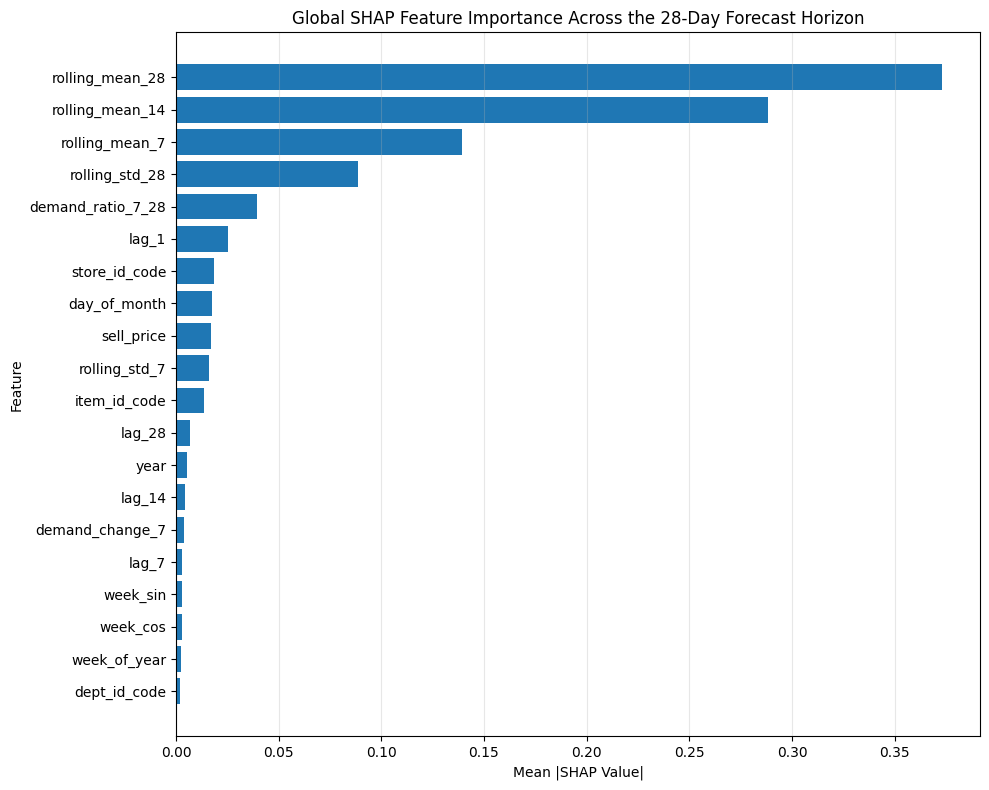

In [ ]:
TOP_N = 20

top_global = (
    global_shap_importance
    .head(TOP_N)
    .sort_values(
        "Mean_Abs_SHAP",
        ascending=True
    )
)

plt.figure(
    figsize=(10, 8)
)

plt.barh(
    top_global["Feature"],
    top_global["Mean_Abs_SHAP"]
)

plt.xlabel(
    "Mean |SHAP Value|"
)

plt.ylabel(
    "Feature"
)

plt.title(
    "Global SHAP Feature Importance "
    "Across the 28-Day Forecast Horizon"
)

plt.grid(
    axis="x",
    alpha=0.3
)

plt.tight_layout()

GLOBAL_SHAP_FIG = os.path.join(
    SHAP_FIGURES_DIR,
    "global_shap_feature_importance.png"
)

plt.savefig(
    GLOBAL_SHAP_FIG,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Calculate day-wise SHAP importance

In [ ]:
daywise_rows = []

for h in range(
    HORIZON
):

    day_importance = np.mean(
        np.abs(
            shap_array[h]
        ),
        axis=0
    )

    for feature, importance in zip(
        FEATURES,
        day_importance
    ):

        daywise_rows.append({

            "Forecast_Day":
                h + 1,

            "Feature":
                feature,

            "Mean_Abs_SHAP":
                float(
                    importance
                )
        })


daywise_shap = pd.DataFrame(
    daywise_rows
)

display(
    daywise_shap.head()
)

,Forecast_Day,Feature,Mean_Abs_SHAP
0,1,lag_1,0.054815
1,1,lag_7,0.000967
2,1,lag_14,0.004157
3,1,lag_28,0.014342
4,1,rolling_mean_7,0.128532


In [ ]:
DAYWISE_SHAP_PATH = os.path.join(
    SHAP_TABLES_DIR,
    "daywise_shap_feature_importance.csv"
)

daywise_shap.to_csv(
    DAYWISE_SHAP_PATH,
    index=False
)

print(
    "Saved:",
    DAYWISE_SHAP_PATH
)

Saved: /content/drive/MyDrive/GC210_Retail_Forecasting/results/shap/tables/daywise_shap_feature_importance.csv


Find top feature for each forecast day

In [ ]:
top_feature_by_day = (
    daywise_shap
    .sort_values(
        [
            "Forecast_Day",
            "Mean_Abs_SHAP"
        ],
        ascending=[
            True,
            False
        ]
    )
    .groupby(
        "Forecast_Day"
    )
    .head(1)
    .reset_index(drop=True)
)

display(
    top_feature_by_day.round(6)
)

,Forecast_Day,Feature,Mean_Abs_SHAP
0,1,rolling_mean_14,0.344973
1,2,rolling_mean_28,0.312744
2,3,rolling_mean_28,0.390915
3,4,rolling_mean_28,0.467297
4,5,rolling_mean_28,0.553966
5,6,rolling_mean_28,0.492474
6,7,rolling_mean_28,0.338026
7,8,rolling_mean_28,0.355843
8,9,rolling_mean_28,0.334941
9,10,rolling_mean_28,0.469984


In [ ]:
TOP_FEATURE_DAY_PATH = os.path.join(
    SHAP_TABLES_DIR,
    "top_shap_feature_by_forecast_day.csv"
)

top_feature_by_day.to_csv(
    TOP_FEATURE_DAY_PATH,
    index=False
)

Create SHAP horizon heatmap

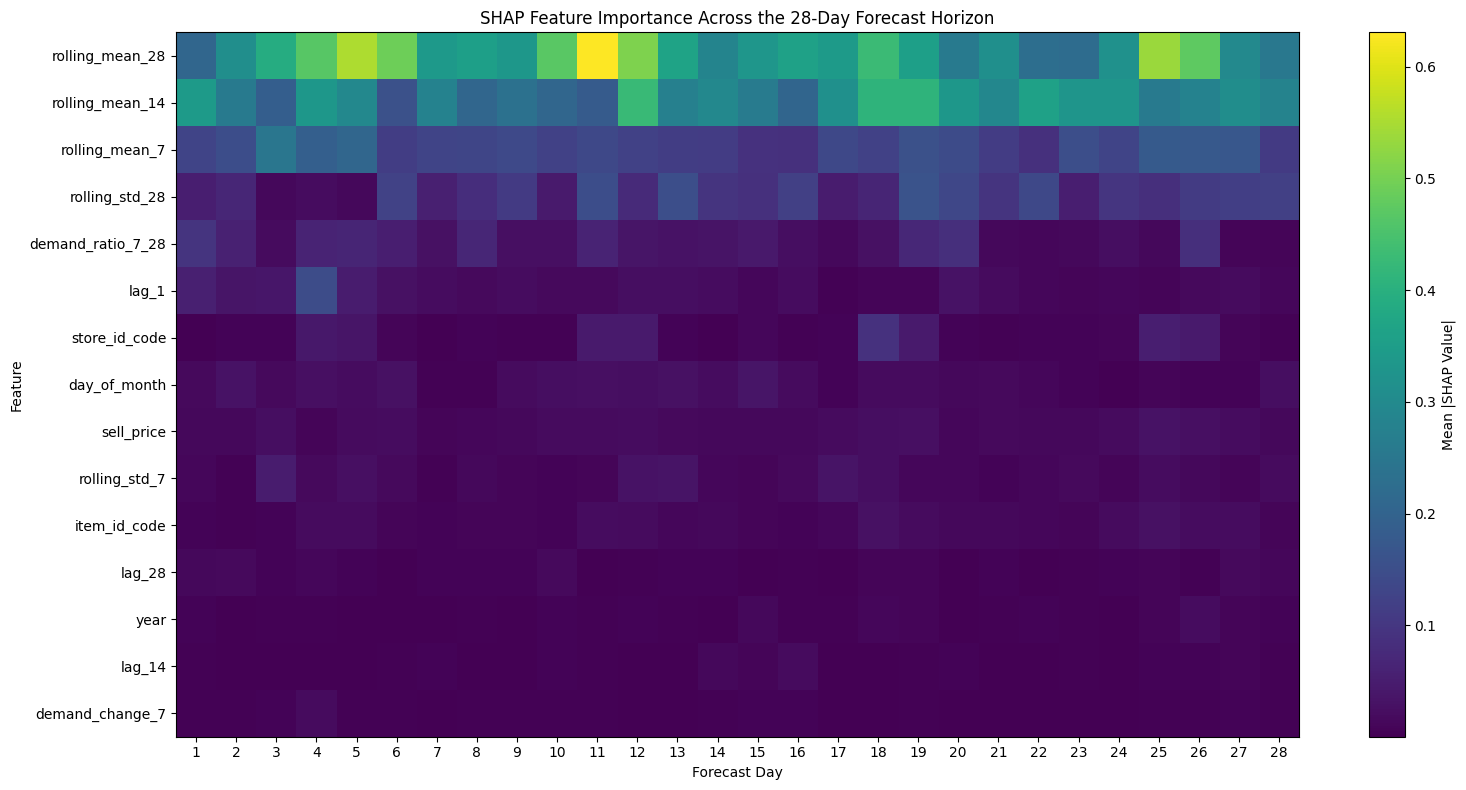

In [ ]:
TOP_HEATMAP_FEATURES = (
    global_shap_importance
    .head(15)[
        "Feature"
    ]
    .tolist()
)

heatmap_data = (
    daywise_shap[
        daywise_shap[
            "Feature"
        ].isin(
            TOP_HEATMAP_FEATURES
        )
    ]
    .pivot(
        index="Feature",
        columns="Forecast_Day",
        values="Mean_Abs_SHAP"
    )
    .reindex(
        TOP_HEATMAP_FEATURES
    )
)

plt.figure(
    figsize=(16, 8)
)

plt.imshow(
    heatmap_data.values,
    aspect="auto"
)

plt.colorbar(
    label="Mean |SHAP Value|"
)

plt.yticks(
    np.arange(
        len(
            heatmap_data.index
        )
    ),
    heatmap_data.index
)

plt.xticks(
    np.arange(
        HORIZON
    ),
    np.arange(
        1,
        HORIZON + 1
    )
)

plt.xlabel(
    "Forecast Day"
)

plt.ylabel(
    "Feature"
)

plt.title(
    "SHAP Feature Importance Across "
    "the 28-Day Forecast Horizon"
)

plt.tight_layout()

SHAP_HEATMAP_FIG = os.path.join(
    SHAP_FIGURES_DIR,
    "shap_horizon_heatmap.png"
)

plt.savefig(
    SHAP_HEATMAP_FIG,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Aggregate SHAP values across 28 days

In [ ]:
mean_signed_shap = np.mean(
    shap_array,
    axis=0
)

print(
    "Aggregated SHAP shape:",
    mean_signed_shap.shape
)

Aggregated SHAP shape: (300, 40)


Global SHAP summary plot

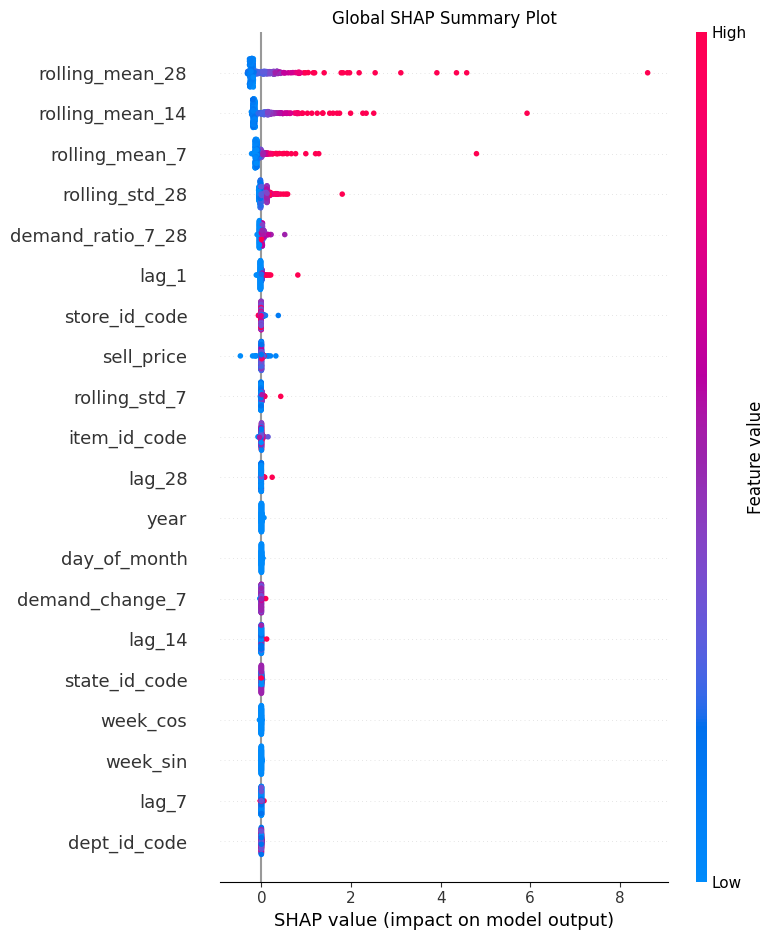

In [ ]:
plt.figure()

shap.summary_plot(
    mean_signed_shap,
    X_shap_sample,
    feature_names=FEATURES,
    max_display=20,
    show=False
)

plt.title(
    "Global SHAP Summary Plot"
)

plt.tight_layout()

SHAP_SUMMARY_FIG = os.path.join(
    SHAP_FIGURES_DIR,
    "global_shap_summary_plot.png"
)

plt.savefig(
    SHAP_SUMMARY_FIG,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Day 1 SHAP summary

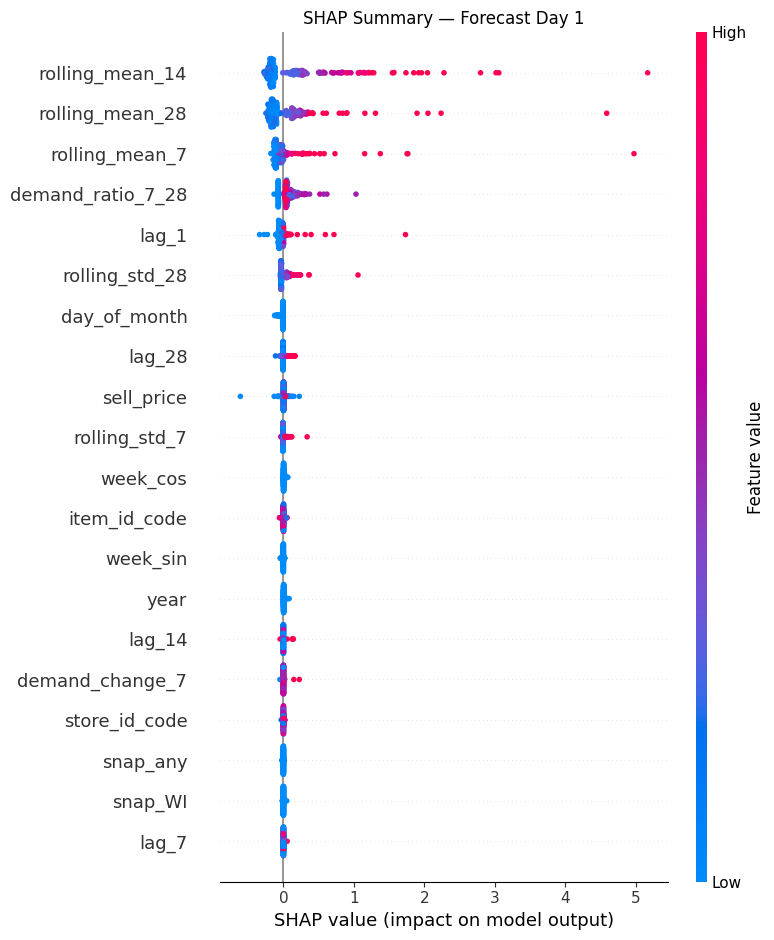

In [ ]:
DAY_1_INDEX = 0

plt.figure()

shap.summary_plot(
    shap_array[
        DAY_1_INDEX
    ],
    X_shap_sample,
    feature_names=FEATURES,
    max_display=20,
    show=False
)

plt.title(
    "SHAP Summary — Forecast Day 1"
)

plt.tight_layout()

DAY1_SHAP_FIG = os.path.join(
    SHAP_FIGURES_DIR,
    "shap_summary_day_01.png"
)

plt.savefig(
    DAY1_SHAP_FIG,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Day 7 SHAP summary

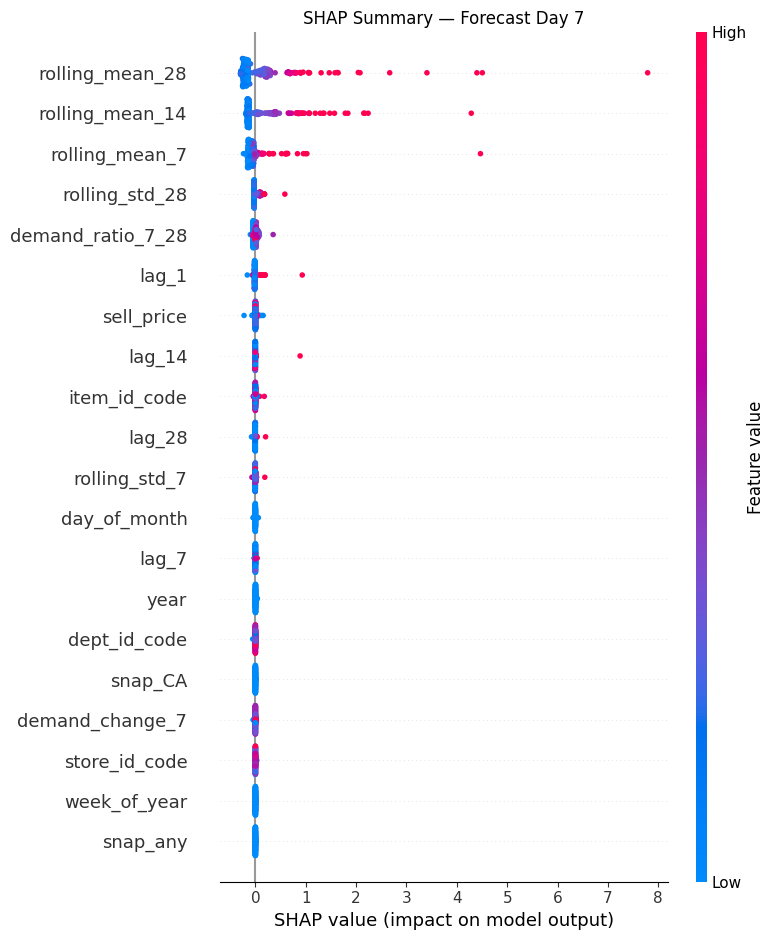

In [ ]:
DAY_7_INDEX = 6

plt.figure()

shap.summary_plot(
    shap_array[
        DAY_7_INDEX
    ],
    X_shap_sample,
    feature_names=FEATURES,
    max_display=20,
    show=False
)

plt.title(
    "SHAP Summary — Forecast Day 7"
)

plt.tight_layout()

DAY7_SHAP_FIG = os.path.join(
    SHAP_FIGURES_DIR,
    "shap_summary_day_07.png"
)

plt.savefig(
    DAY7_SHAP_FIG,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

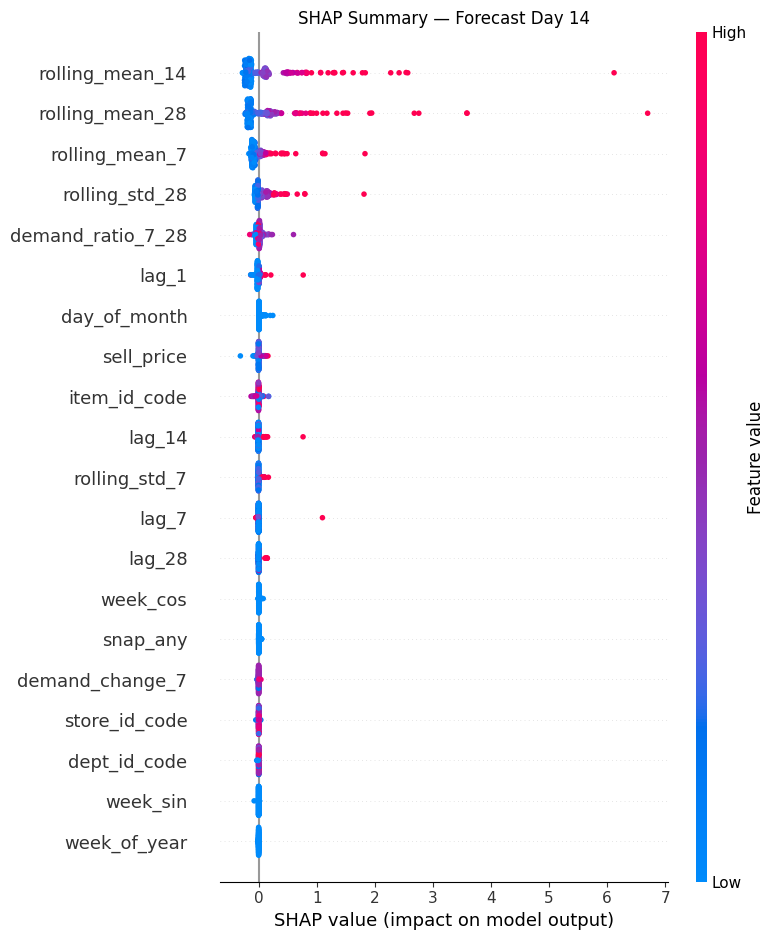

In [ ]:
DAY_14_INDEX = 13

plt.figure()

shap.summary_plot(
    shap_array[
        DAY_14_INDEX
    ],
    X_shap_sample,
    feature_names=FEATURES,
    max_display=20,
    show=False
)

plt.title(
    "SHAP Summary — Forecast Day 14"
)

plt.tight_layout()

DAY14_SHAP_FIG = os.path.join(
    SHAP_FIGURES_DIR,
    "shap_summary_day_14.png"
)

plt.savefig(
    DAY14_SHAP_FIG,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Day 28 SHAP summary

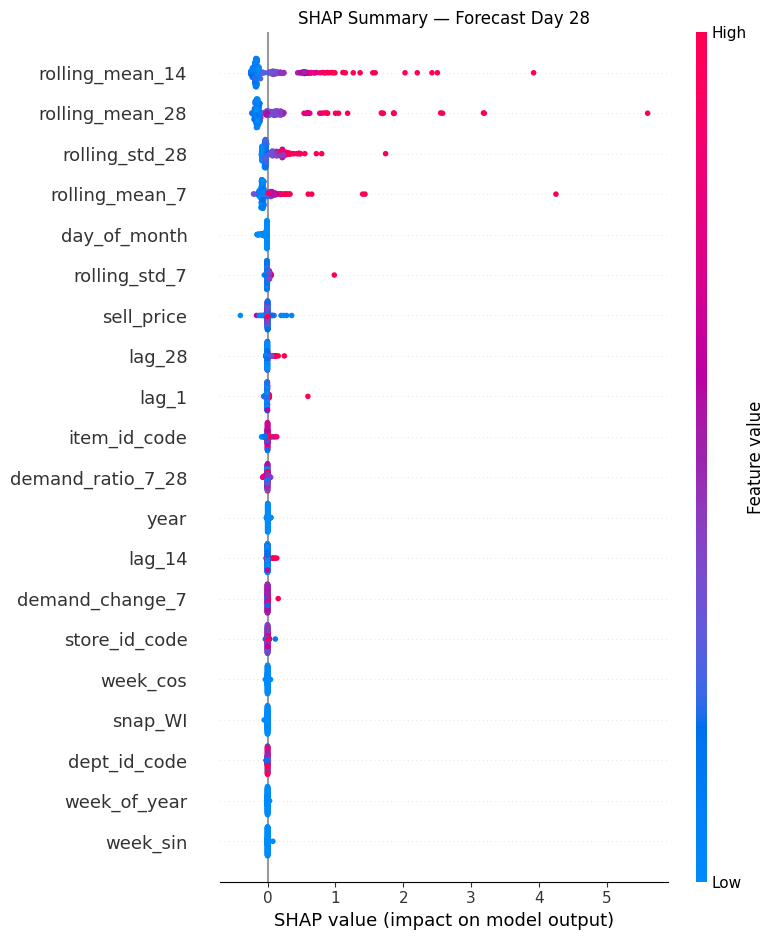

In [ ]:
DAY_28_INDEX = 27

plt.figure()

shap.summary_plot(
    shap_array[
        DAY_28_INDEX
    ],
    X_shap_sample,
    feature_names=FEATURES,
    max_display=20,
    show=False
)

plt.title(
    "SHAP Summary — Forecast Day 28"
)

plt.tight_layout()

DAY28_SHAP_FIG = os.path.join(
    SHAP_FIGURES_DIR,
    "shap_summary_day_28.png"
)

plt.savefig(
    DAY28_SHAP_FIG,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Automatically select the top five features

In [ ]:
TOP_FEATURES = (
    global_shap_importance
    .head(5)[
        "Feature"
    ]
    .tolist()
)

print(
    "Top five SHAP features:"
)

for i, feature in enumerate(
    TOP_FEATURES,
    start=1
):
    print(
        f"{i}. {feature}"
    )

Top five SHAP features:
1. rolling_mean_28
2. rolling_mean_14
3. rolling_mean_7
4. rolling_std_28
5. demand_ratio_7_28


Dependence plot for top feature

<Figure size 640x480 with 0 Axes>

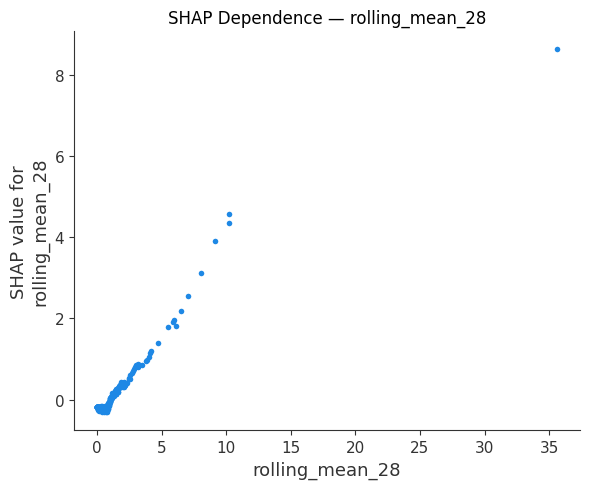

In [ ]:
TOP_FEATURE_1 = TOP_FEATURES[0]

plt.figure()

shap.dependence_plot(
    TOP_FEATURE_1,
    mean_signed_shap,
    X_shap_sample,
    feature_names=FEATURES,
    interaction_index=None,
    show=False
)

plt.title(
    f"SHAP Dependence — {TOP_FEATURE_1}"
)

plt.tight_layout()

DEPENDENCE_1_FIG = os.path.join(
    SHAP_FIGURES_DIR,
    f"dependence_{TOP_FEATURE_1}.png"
)

plt.savefig(
    DEPENDENCE_1_FIG,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Generate dependence plots for top five features

<Figure size 640x480 with 0 Axes>

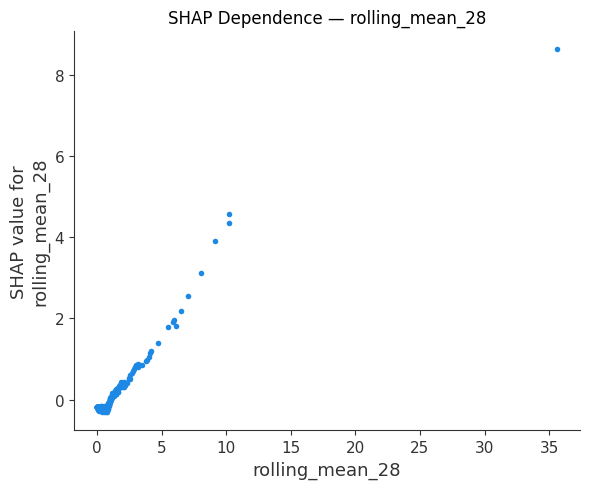

<Figure size 640x480 with 0 Axes>

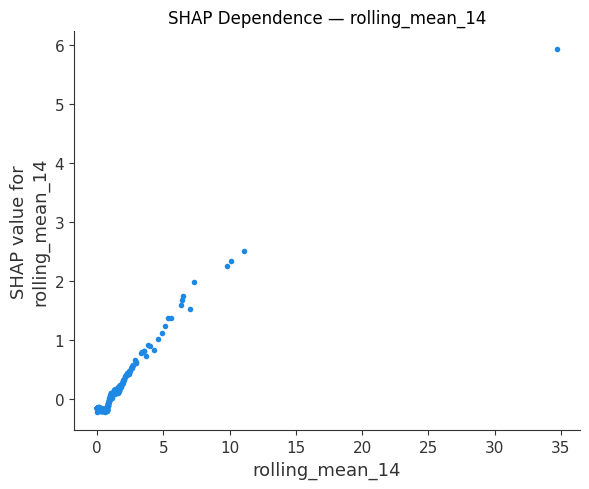

<Figure size 640x480 with 0 Axes>

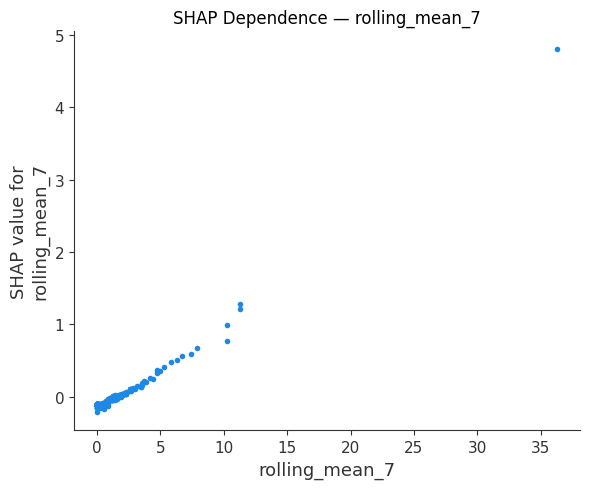

<Figure size 640x480 with 0 Axes>

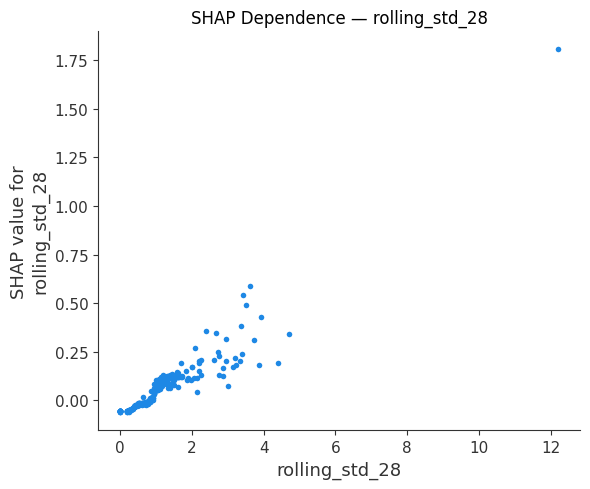

<Figure size 640x480 with 0 Axes>

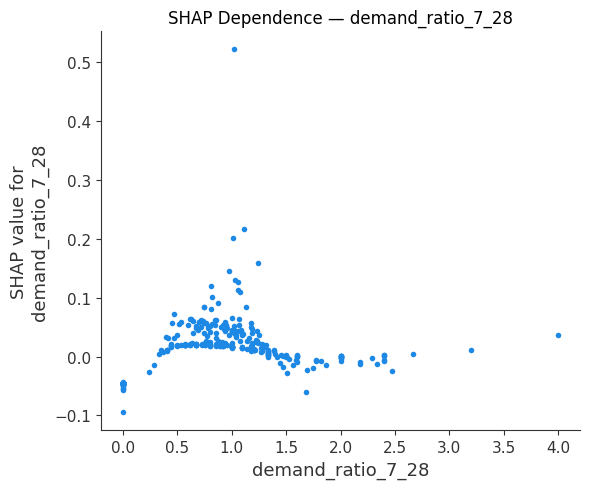

In [ ]:
dependence_paths = []

for feature in TOP_FEATURES:

    plt.figure()

    shap.dependence_plot(
        feature,
        mean_signed_shap,
        X_shap_sample,
        feature_names=FEATURES,
        interaction_index=None,
        show=False
    )

    plt.title(
        f"SHAP Dependence — {feature}"
    )

    plt.tight_layout()

    safe_feature = (
        feature
        .replace("/", "_")
        .replace(" ", "_")
    )

    path = os.path.join(
        SHAP_FIGURES_DIR,
        f"shap_dependence_{safe_feature}.png"
    )

    plt.savefig(
        path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    dependence_paths.append(
        path
    )

Feature-family analysis

In [ ]:
feature_groups = {

    "Lag Features": [
        "lag_1",
        "lag_7",
        "lag_14",
        "lag_28"
    ],

    "Rolling Demand": [
        "rolling_mean_7",
        "rolling_mean_14",
        "rolling_mean_28",
        "rolling_std_7",
        "rolling_std_28",
        "demand_ratio_7_28",
        "demand_change_7"
    ],

    "Price": [
        "sell_price",
        "price_change",
        "price_change_pct",
        "price_volatility_7"
    ],

    "Calendar": [
        "day_of_week",
        "day_of_month",
        "week_of_year",
        "month",
        "quarter",
        "year",
        "is_weekend"
    ],

    "Cyclical Time": [
        "dow_sin",
        "dow_cos",
        "month_sin",
        "month_cos",
        "week_sin",
        "week_cos"
    ],

    "Events": [
        "has_event_1",
        "has_event_2",
        "has_event"
    ],

    "SNAP": [
        "snap_CA",
        "snap_TX",
        "snap_WI",
        "snap_any"
    ],

    "Hierarchy": [
        "item_id_code",
        "dept_id_code",
        "cat_id_code",
        "store_id_code",
        "state_id_code"
    ]
}

Calculate feature-family SHAP importance

In [ ]:
feature_importance_map = dict(
    zip(
        global_shap_importance[
            "Feature"
        ],
        global_shap_importance[
            "Mean_Abs_SHAP"
        ]
    )
)

group_rows = []

for group_name, group_features in (
    feature_groups.items()
):

    available_features = [
        feature
        for feature in group_features
        if feature in feature_importance_map
    ]

    total_importance = sum(
        feature_importance_map[
            feature
        ]
        for feature in available_features
    )

    mean_importance = (
        total_importance
        /
        len(available_features)
        if available_features
        else 0
    )

    group_rows.append({

        "Feature_Group":
            group_name,

        "Number_of_Features":
            len(
                available_features
            ),

        "Total_Mean_Abs_SHAP":
            total_importance,

        "Average_Mean_Abs_SHAP":
            mean_importance
    })


feature_group_importance = pd.DataFrame(
    group_rows
)

feature_group_importance = (
    feature_group_importance
    .sort_values(
        "Total_Mean_Abs_SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    feature_group_importance.round(6)
)

,Feature_Group,Number_of_Features,Total_Mean_Abs_SHAP,Average_Mean_Abs_SHAP
0,Rolling Demand,7,0.948857,0.135551
1,Lag Features,4,0.039204,0.009801
2,Hierarchy,5,0.036192,0.007238
3,Calendar,7,0.025511,0.003644
4,Price,4,0.017645,0.004411
5,Cyclical Time,6,0.007271,0.001212
6,SNAP,4,0.001981,0.000495
7,Events,3,0.000061,0.000020


Save feature-family results

In [ ]:
FEATURE_GROUP_PATH = os.path.join(
    SHAP_TABLES_DIR,
    "shap_feature_group_importance.csv"
)

feature_group_importance.to_csv(
    FEATURE_GROUP_PATH,
    index=False
)

print(
    "Saved:",
    FEATURE_GROUP_PATH
)

Saved: /content/drive/MyDrive/GC210_Retail_Forecasting/results/shap/tables/shap_feature_group_importance.csv


Plot feature-family importance

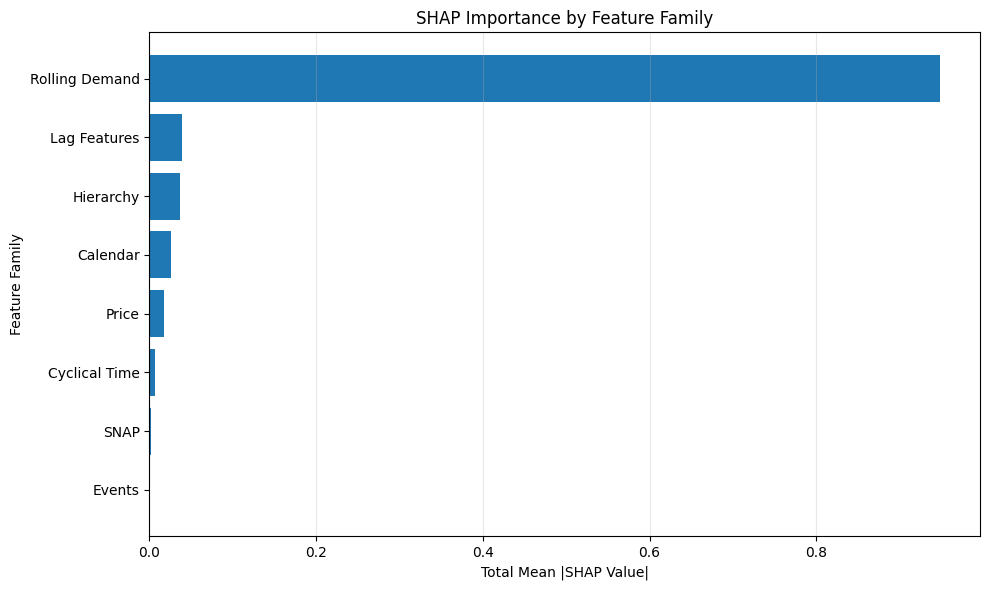

In [ ]:
group_plot = (
    feature_group_importance
    .sort_values(
        "Total_Mean_Abs_SHAP",
        ascending=True
    )
)

plt.figure(
    figsize=(10, 6)
)

plt.barh(
    group_plot[
        "Feature_Group"
    ],
    group_plot[
        "Total_Mean_Abs_SHAP"
    ]
)

plt.xlabel(
    "Total Mean |SHAP Value|"
)

plt.ylabel(
    "Feature Family"
)

plt.title(
    "SHAP Importance by Feature Family"
)

plt.grid(
    axis="x",
    alpha=0.3
)

plt.tight_layout()

FEATURE_GROUP_FIG = os.path.join(
    SHAP_FIGURES_DIR,
    "shap_feature_group_importance.png"
)

plt.savefig(
    FEATURE_GROUP_FIG,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Short-, medium-, and long-horizon SHAP analysis

In [ ]:
horizon_ranges = {

    "Short_1_7":
        range(0, 7),

    "Medium_8_14":
        range(7, 14),

    "Long_15_28":
        range(14, 28)
}

horizon_importance_rows = []

for horizon_name, indices in (
    horizon_ranges.items()
):

    subset = shap_array[
        list(indices)
    ]

    importance = np.mean(
        np.abs(
            subset
        ),
        axis=(0, 1)
    )

    for feature, value in zip(
        FEATURES,
        importance
    ):

        horizon_importance_rows.append({

            "Horizon_Group":
                horizon_name,

            "Feature":
                feature,

            "Mean_Abs_SHAP":
                float(value)
        })


horizon_shap_groups = pd.DataFrame(
    horizon_importance_rows
)

display(
    horizon_shap_groups.head()
)

,Horizon_Group,Feature,Mean_Abs_SHAP
0,Short_1_7,lag_1,0.053660
1,Short_1_7,lag_7,0.002009
2,Short_1_7,lag_14,0.002796
3,Short_1_7,lag_28,0.008506
4,Short_1_7,rolling_mean_7,0.167176


In [ ]:
HORIZON_GROUP_SHAP_PATH = os.path.join(
    SHAP_TABLES_DIR,
    "shap_short_medium_long_horizon.csv"
)

horizon_shap_groups.to_csv(
    HORIZON_GROUP_SHAP_PATH,
    index=False
)

Top 10 features by horizon group

In [ ]:
top_horizon_features = (
    horizon_shap_groups
    .sort_values(
        [
            "Horizon_Group",
            "Mean_Abs_SHAP"
        ],
        ascending=[
            True,
            False
        ]
    )
    .groupby(
        "Horizon_Group"
    )
    .head(10)
    .reset_index(drop=True)
)

display(
    top_horizon_features.round(6)
)

,Horizon_Group,Feature,Mean_Abs_SHAP
0,Long_15_28,rolling_mean_28,0.337619
1,Long_15_28,rolling_mean_14,0.313008
2,Long_15_28,rolling_mean_7,0.132259
3,Long_15_28,rolling_std_28,0.101984
4,Long_15_28,demand_ratio_7_28,0.031676
5,Long_15_28,store_id_code,0.021267
6,Long_15_28,sell_price,0.018565
7,Long_15_28,item_id_code,0.015981
8,Long_15_28,rolling_std_7,0.015110
9,Long_15_28,day_of_month,0.013888


Save top horizon features

In [ ]:
TOP_HORIZON_PATH = os.path.join(
    SHAP_TABLES_DIR,
    "top_features_by_horizon_group.csv"
)

top_horizon_features.to_csv(
    TOP_HORIZON_PATH,
    index=False
)

Individual prediction explanation

In [ ]:
SAMPLE_INDEX = 0
FORECAST_DAY = 1

day_idx = FORECAST_DAY - 1

sample_features = (
    X_shap_sample
    .iloc[
        SAMPLE_INDEX
    ]
)

sample_shap = (
    shap_array[
        day_idx,
        SAMPLE_INDEX
    ]
)

individual_explanation = pd.DataFrame({

    "Feature":
        FEATURES,

    "Feature_Value":
        sample_features.values,

    "SHAP_Value":
        sample_shap,

    "Abs_SHAP":
        np.abs(
            sample_shap
        )
})

individual_explanation = (
    individual_explanation
    .sort_values(
        "Abs_SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    individual_explanation
    .head(15)
    .round(6)
)

,Feature,Feature_Value,SHAP_Value,Abs_SHAP
0,rolling_mean_28,0.750000,-0.223581,0.223581
1,lag_1,5.000000,0.037842,0.037842
2,sell_price,0.970000,-0.035513,0.035513
3,item_id_code,192.000000,-0.035344,0.035344
4,rolling_mean_14,1.142857,0.035014,0.035014
5,rolling_std_7,2.115701,-0.033312,0.033312
6,rolling_std_28,1.404358,-0.032971,0.032971
7,demand_ratio_7_28,2.476187,0.032946,0.032946
8,day_of_month,24.000000,-0.009231,0.009231
9,lag_28,0.000000,-0.009188,0.009188


Save individual explanation

In [ ]:
INDIVIDUAL_EXPLANATION_PATH = os.path.join(
    SHAP_TABLES_DIR,
    "example_individual_forecast_explanation.csv"
)

individual_explanation.to_csv(
    INDIVIDUAL_EXPLANATION_PATH,
    index=False
)

print(
    "Saved:",
    INDIVIDUAL_EXPLANATION_PATH
)

Saved: /content/drive/MyDrive/GC210_Retail_Forecasting/results/shap/tables/example_individual_forecast_explanation.csv


Waterfall plot for individual prediction

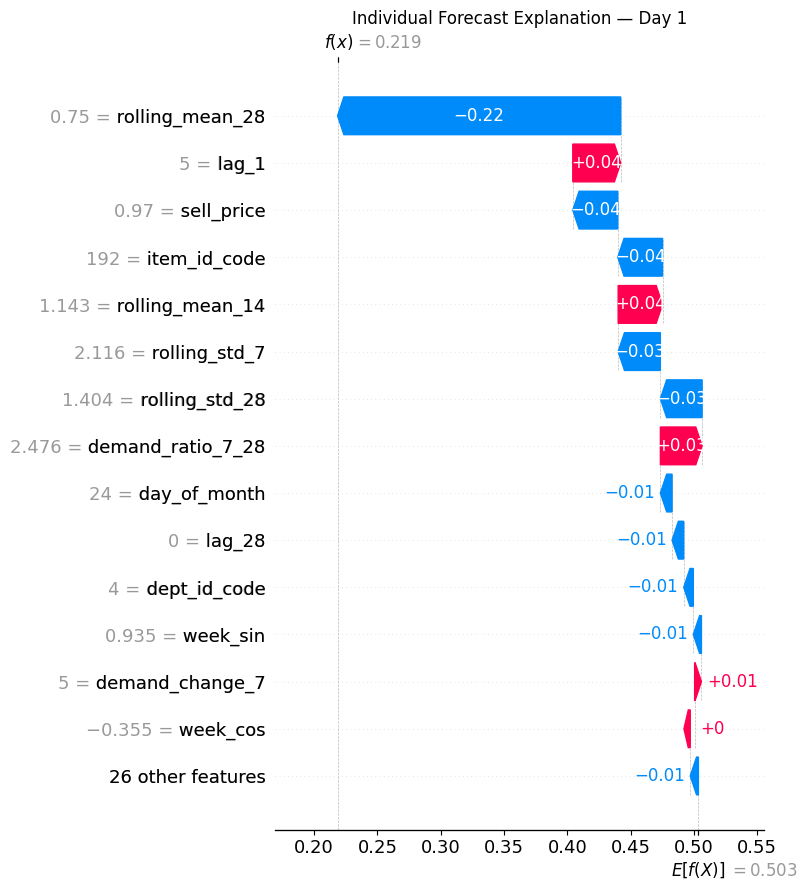

In [ ]:
sample_explanation = shap.Explanation(

    values=sample_shap,

    base_values=all_expected_values[
        day_idx
    ],

    data=sample_features.values,

    feature_names=FEATURES
)

plt.figure()

shap.plots.waterfall(
    sample_explanation,
    max_display=15,
    show=False
)

plt.title(
    f"Individual Forecast Explanation — "
    f"Day {FORECAST_DAY}"
)

plt.tight_layout()

WATERFALL_FIG = os.path.join(
    SHAP_FIGURES_DIR,
    "individual_forecast_waterfall_day01.png"
)

plt.savefig(
    WATERFALL_FIG,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Compare SHAP with native LightGBM importance

In [ ]:
LGBM_IMPORTANCE_PATH = os.path.join(
    METRICS_DIR,
    "lightgbm_feature_importance.csv"
)

if os.path.exists(
    LGBM_IMPORTANCE_PATH
):

    lgbm_importance = pd.read_csv(
        LGBM_IMPORTANCE_PATH
    )

    print(
        "Native LightGBM importance loaded."
    )

    display(
        lgbm_importance.head()
    )

else:

    lgbm_importance = None

    print(
        "Native LightGBM importance file "
        "not found. Skipping comparison."
    )

Native LightGBM importance loaded.


,Feature,Importance
0,rolling_mean_28,1714.571429
1,rolling_std_28,1063.321429
2,demand_ratio_7_28,788.285714
3,rolling_mean_7,727.035714
4,rolling_mean_14,709.571429


Merge SHAP and LightGBM importance

In [ ]:
if lgbm_importance is not None:

    feature_col = None

    for candidate in [
        "Feature",
        "feature"
    ]:

        if candidate in (
            lgbm_importance.columns
        ):

            feature_col = candidate
            break

    importance_candidates = [
        col
        for col in lgbm_importance.columns
        if col != feature_col
        and pd.api.types.is_numeric_dtype(
            lgbm_importance[col]
        )
    ]

    if (
        feature_col is not None
        and
        len(
            importance_candidates
        ) > 0
    ):

        native_importance_col = (
            importance_candidates[0]
        )

        comparison_importance = (
            global_shap_importance
            .merge(
                lgbm_importance[
                    [
                        feature_col,
                        native_importance_col
                    ]
                ],
                left_on="Feature",
                right_on=feature_col,
                how="left"
            )
        )

        display(
            comparison_importance
            .head(20)
            .round(6)
        )

,Rank,Feature,Mean_Abs_SHAP,Importance
0,1,rolling_mean_28,0.372954,1714.571429
1,2,rolling_mean_14,0.288295,709.571429
2,3,rolling_mean_7,0.139384,727.035714
3,4,rolling_std_28,0.088617,1063.321429
4,5,demand_ratio_7_28,0.039634,788.285714
5,6,lag_1,0.025076,102.928571
6,7,store_id_code,0.018372,235.607143
7,8,day_of_month,0.017280,404.142857
8,9,sell_price,0.017075,569.500000
9,10,rolling_std_7,0.015965,490.464286


Create SHAP interpretation summary table

In [ ]:
interpretation_table = (
    global_shap_importance
    .head(15)
    .copy()
)

interpretation_table[
    "Feature_Group"
] = "Other"

for idx, row in (
    interpretation_table
    .iterrows()
):

    feature = row["Feature"]

    for group_name, group_features in (
        feature_groups.items()
    ):

        if feature in group_features:

            interpretation_table.loc[
                idx,
                "Feature_Group"
            ] = group_name

            break

display(
    interpretation_table.round(6)
)

,Rank,Feature,Mean_Abs_SHAP,Feature_Group
0,1,rolling_mean_28,0.372954,Rolling Demand
1,2,rolling_mean_14,0.288295,Rolling Demand
2,3,rolling_mean_7,0.139384,Rolling Demand
3,4,rolling_std_28,0.088617,Rolling Demand
4,5,demand_ratio_7_28,0.039634,Rolling Demand
5,6,lag_1,0.025076,Lag Features
6,7,store_id_code,0.018372,Hierarchy
7,8,day_of_month,0.017280,Calendar
8,9,sell_price,0.017075,Price
9,10,rolling_std_7,0.015965,Rolling Demand


In [ ]:
INTERPRETATION_PATH = os.path.join(
    SHAP_TABLES_DIR,
    "top15_shap_interpretation_table.csv"
)

interpretation_table.to_csv(
    INTERPRETATION_PATH,
    index=False
)

Create normalized importance percentages

In [ ]:
total_shap = (
    global_shap_importance[
        "Mean_Abs_SHAP"
    ]
    .sum()
)

global_shap_percentage = (
    global_shap_importance
    .copy()
)

global_shap_percentage[
    "Importance_Percentage"
] = (
    global_shap_percentage[
        "Mean_Abs_SHAP"
    ]
    /
    total_shap
    * 100
)

global_shap_percentage[
    "Cumulative_Importance_Percentage"
] = (
    global_shap_percentage[
        "Importance_Percentage"
    ]
    .cumsum()
)

display(
    global_shap_percentage
    .head(20)
    .round(4)
)

,Rank,Feature,Mean_Abs_SHAP,Importance_Percentage,Cumulative_Importance_Percentage
0,1,rolling_mean_28,0.3730,34.6379,34.6379
1,2,rolling_mean_14,0.2883,26.7752,61.4131
2,3,rolling_mean_7,0.1394,12.9452,74.3583
3,4,rolling_std_28,0.0886,8.2302,82.5885
4,5,demand_ratio_7_28,0.0396,3.6810,86.2695
5,6,lag_1,0.0251,2.3289,88.5984
6,7,store_id_code,0.0184,1.7063,90.3047
7,8,day_of_month,0.0173,1.6048,91.9096
8,9,sell_price,0.0171,1.5859,93.4954
9,10,rolling_std_7,0.0160,1.4828,94.9782


In [ ]:
SHAP_PERCENTAGE_PATH = os.path.join(
    SHAP_TABLES_DIR,
    "global_shap_importance_percentage.csv"
)

global_shap_percentage.to_csv(
    SHAP_PERCENTAGE_PATH,
    index=False
)

Plot cumulative SHAP importance

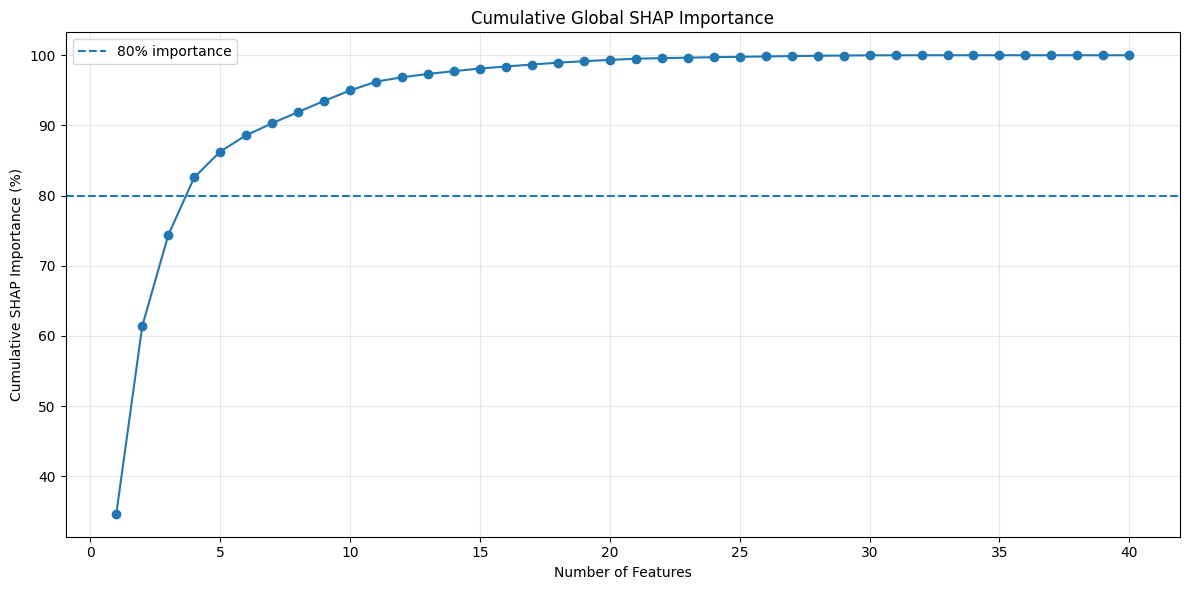

In [ ]:
plt.figure(
    figsize=(12, 6)
)

plt.plot(
    np.arange(
        1,
        len(
            global_shap_percentage
        ) + 1
    ),
    global_shap_percentage[
        "Cumulative_Importance_Percentage"
    ],
    marker="o"
)

plt.axhline(
    80,
    linestyle="--",
    label="80% importance"
)

plt.xlabel(
    "Number of Features"
)

plt.ylabel(
    "Cumulative SHAP Importance (%)"
)

plt.title(
    "Cumulative Global SHAP Importance"
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

CUMULATIVE_SHAP_FIG = os.path.join(
    SHAP_FIGURES_DIR,
    "cumulative_shap_importance.png"
)

plt.savefig(
    CUMULATIVE_SHAP_FIG,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Determine features accounting for 80% of SHAP importance

In [ ]:
cumulative_values = (
    global_shap_percentage[
        "Cumulative_Importance_Percentage"
    ]
    .to_numpy()
)

threshold_indices = np.where(
    cumulative_values >= 80
)[0]

if len(
    threshold_indices
) > 0:

    n_features_80 = (
        threshold_indices[0] + 1
    )

else:

    n_features_80 = len(
        global_shap_percentage
    )

print(
    "Number of features accounting for "
    "approximately 80% of total SHAP importance:",
    n_features_80
)

display(
    global_shap_percentage
    .head(
        n_features_80
    )
    .round(4)
)

Number of features accounting for approximately 80% of total SHAP importance: 4


,Rank,Feature,Mean_Abs_SHAP,Importance_Percentage,Cumulative_Importance_Percentage
0,1,rolling_mean_28,0.3730,34.6379,34.6379
1,2,rolling_mean_14,0.2883,26.7752,61.4131
2,3,rolling_mean_7,0.1394,12.9452,74.3583
3,4,rolling_std_28,0.0886,8.2302,82.5885


Save SHAP arrays for future analysis

In [ ]:
SHAP_ARRAY_PATH = os.path.join(
    SHAP_DIR,
    "lightgbm_shap_values_28day.npz"
)

np.savez_compressed(
    SHAP_ARRAY_PATH,

    shap_values=
        shap_array,

    feature_values=
        X_shap_sample
        .to_numpy(
            dtype=np.float32
        ),

    feature_names=
        np.array(
            FEATURES
        ),

    expected_values=
        np.array(
            all_expected_values
        )
)

print(
    "Saved:",
    SHAP_ARRAY_PATH
)

Saved: /content/drive/MyDrive/GC210_Retail_Forecasting/results/shap/lightgbm_shap_values_28day.npz


Save SHAP arrays for future analysis

In [ ]:
SHAP_ARRAY_PATH = os.path.join(
    SHAP_DIR,
    "lightgbm_shap_values_28day.npz"
)

np.savez_compressed(
    SHAP_ARRAY_PATH,

    shap_values=
        shap_array,

    feature_values=
        X_shap_sample
        .to_numpy(
            dtype=np.float32
        ),

    feature_names=
        np.array(
            FEATURES
        ),

    expected_values=
        np.array(
            all_expected_values
        )
)

print(
    "Saved:",
    SHAP_ARRAY_PATH
)

Saved: /content/drive/MyDrive/GC210_Retail_Forecasting/results/shap/lightgbm_shap_values_28day.npz


Save explainability configuration

In [ ]:
shap_config = {

    "model":
        "LightGBM",

    "forecast_horizon":
        HORIZON,

    "number_of_features":
        len(FEATURES),

    "number_of_samples":
        len(X_shap_sample),

    "explainer":
        "TreeExplainer",

    "global_importance":
        "Mean absolute SHAP value",

    "horizon_analysis": {
        "short":
            "Day 1-7",

        "medium":
            "Day 8-14",

        "long":
            "Day 15-28"
    },

    "feature_groups":
        list(
            feature_groups.keys()
        )
}

SHAP_CONFIG_PATH = os.path.join(
    SHAP_DIR,
    "shap_config.json"
)

with open(
    SHAP_CONFIG_PATH,
    "w"
) as f:

    json.dump(
        shap_config,
        f,
        indent=4
    )

print(
    "Saved:",
    SHAP_CONFIG_PATH
)

Saved: /content/drive/MyDrive/GC210_Retail_Forecasting/results/shap/shap_config.json


Print top 15 explanatory features

In [ ]:
print("=" * 75)
print("TOP 15 LIGHTGBM FEATURES ACCORDING TO SHAP")
print("=" * 75)

for _, row in (
    global_shap_importance
    .head(15)
    .iterrows()
):

    print(
        f"{int(row['Rank']):02d}. "
        f"{row['Feature']:25s} "
        f"{row['Mean_Abs_SHAP']:.6f}"
    )

print("=" * 75)

TOP 15 LIGHTGBM FEATURES ACCORDING TO SHAP
01. rolling_mean_28           0.372954
02. rolling_mean_14           0.288295
03. rolling_mean_7            0.139384
04. rolling_std_28            0.088617
05. demand_ratio_7_28         0.039634
06. lag_1                     0.025076
07. store_id_code             0.018372
08. day_of_month              0.017280
09. sell_price                0.017075
10. rolling_std_7             0.015965
11. item_id_code              0.013573
12. lag_28                    0.006701
13. year                      0.005106
14. lag_14                    0.004316
15. demand_change_7           0.004008


Print feature-family results

In [ ]:
print("=" * 75)
print("SHAP IMPORTANCE BY FEATURE FAMILY")
print("=" * 75)

print(
    feature_group_importance
    .round(6)
    .to_string(
        index=False
    )
)

print("=" * 75)

SHAP IMPORTANCE BY FEATURE FAMILY
 Feature_Group  Number_of_Features  Total_Mean_Abs_SHAP  Average_Mean_Abs_SHAP
Rolling Demand                   7             0.948857               0.135551
  Lag Features                   4             0.039204               0.009801
     Hierarchy                   5             0.036192               0.007238
      Calendar                   7             0.025511               0.003644
         Price                   4             0.017645               0.004411
 Cyclical Time                   6             0.007271               0.001212
          SNAP                   4             0.001981               0.000495
        Events                   3             0.000061               0.000020


Final verification

In [ ]:
print("=" * 90)
print("STEP 14 - SHAP EXPLAINABILITY FINAL VERIFICATION")
print("=" * 90)

print("\n1. MODEL")
print("-" * 60)

print(
    "Explained model     : LightGBM"
)

print(
    "Horizon models      :",
    len(
        lightgbm_models
    )
)

print(
    "Input features      :",
    len(
        FEATURES
    )
)

print(
    "SHAP samples        :",
    len(
        X_shap_sample
    )
)


print("\n2. SHAP ARRAY")
print("-" * 60)

print(
    "Shape:",
    shap_array.shape
)

print(
    "Expected:",
    (
        HORIZON,
        len(
            X_shap_sample
        ),
        len(
            FEATURES
        )
    )
)

print(
    "Finite:",
    np.isfinite(
        shap_array
    ).all()
)


print("\n3. ANALYSES COMPLETED")
print("-" * 60)

analysis_list = [
    "Global feature importance",
    "28-day feature importance",
    "SHAP summary plots",
    "Dependence plots",
    "Feature-family analysis",
    "Short/medium/long horizon analysis",
    "Individual forecast explanation",
    "Cumulative feature importance"
]

for analysis in analysis_list:

    print(
        "✓",
        analysis
    )


print("\n4. OUTPUT FILES")
print("-" * 60)

files_to_check = {

    "Global SHAP importance":
        GLOBAL_SHAP_PATH,

    "Day-wise importance":
        DAYWISE_SHAP_PATH,

    "Top feature by day":
        TOP_FEATURE_DAY_PATH,

    "Feature groups":
        FEATURE_GROUP_PATH,

    "Horizon groups":
        HORIZON_GROUP_SHAP_PATH,

    "Top horizon features":
        TOP_HORIZON_PATH,

    "Individual explanation":
        INDIVIDUAL_EXPLANATION_PATH,

    "Interpretation table":
        INTERPRETATION_PATH,

    "Importance percentage":
        SHAP_PERCENTAGE_PATH,

    "SHAP array":
        SHAP_ARRAY_PATH,

    "SHAP config":
        SHAP_CONFIG_PATH,

    "Global importance figure":
        GLOBAL_SHAP_FIG,

    "Global summary figure":
        SHAP_SUMMARY_FIG,

    "Horizon heatmap":
        SHAP_HEATMAP_FIG,

    "Feature-group figure":
        FEATURE_GROUP_FIG,

    "Waterfall figure":
        WATERFALL_FIG,

    "Cumulative figure":
        CUMULATIVE_SHAP_FIG
}

all_saved = True

for name, path in (
    files_to_check.items()
):

    exists = os.path.exists(
        path
    )

    print(
        f"{name:30s}:",
        "FOUND"
        if exists
        else "MISSING"
    )

    if not exists:
        all_saved = False


print("\n" + "=" * 90)

if all_saved:

    print(
        "STEP 14 COMPLETED SUCCESSFULLY"
    )

    print(
        "LIGHTGBM -> 28-DAY FORECAST -> "
        "SHAP -> GLOBAL + HORIZON + "
        "LOCAL EXPLAINABILITY"
    )

else:

    print(
        "STEP 14 INCOMPLETE - "
        "CHECK MISSING FILES ABOVE"
    )

print("=" * 90)

STEP 14 - SHAP EXPLAINABILITY FINAL VERIFICATION

1. MODEL
------------------------------------------------------------
Explained model     : LightGBM
Horizon models      : 28
Input features      : 40
SHAP samples        : 300

2. SHAP ARRAY
------------------------------------------------------------
Shape: (28, 300, 40)
Expected: (28, 300, 40)
Finite: True

3. ANALYSES COMPLETED
------------------------------------------------------------
✓ Global feature importance
✓ 28-day feature importance
✓ SHAP summary plots
✓ Dependence plots
✓ Feature-family analysis
✓ Short/medium/long horizon analysis
✓ Individual forecast explanation
✓ Cumulative feature importance

4. OUTPUT FILES
------------------------------------------------------------
Global SHAP importance        : FOUND
Day-wise importance           : FOUND
Top feature by day            : FOUND
Feature groups                : FOUND
Horizon groups                : FOUND
Top horizon features          : FOUND
Individual explanation  